# DIP Assignment 1 — Problem 2: Bit-plane slicing and steganography

**Name:** Kushal Mukherjee &nbsp;&nbsp; **Roll number:** 2025201072

In [1]:
import time
import platform
import subprocess

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

ROOT = Path.cwd()

print("CPU    :", subprocess.check_output(["sysctl", "-n", "machdep.cpu.brand_string"]).decode().strip())
print("Cores  :", subprocess.check_output(["sysctl", "-n", "hw.ncpu"]).decode().strip())
print("RAM    :", round(int(subprocess.check_output(["sysctl", "-n", "hw.memsize"])) / 1e9), "GB")
print("OS     :", platform.platform())
print("Python :", platform.python_version())
print("NumPy  :", np.__version__)

CPU    : Apple M4
Cores  : 10
RAM    : 17 GB
OS     : macOS-15.7.7-arm64-arm-64bit-Mach-O
Python : 3.13.9
NumPy  : 2.4.1


In [2]:
def psnr(a, b, peak=255.0):
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(peak * peak / mse)

---
# Problem 2 — Bit-plane slicing and steganography

Covers: `images/p2/cover_textured.png`, `images/p2/cover_smooth.png` (both 1024x1024).
Supplied stego image: `images/p2/decode_me.png`, whose clean cover is the textured one.

In [3]:
def bit_planes(img):
    """(H,W) uint8 -> (8,H,W) uint8 in {0,1}, index 0 = LSB."""
    return np.array([(img >> b) & 1 for b in range(8)], dtype=np.uint8)


def reconstruct(planes, keep):
    """Rebuild from the `keep` most significant planes."""
    result = np.zeros(planes.shape[1:], dtype=np.uint8)

    for b in range(8 - keep, 8):
        result += planes[b] * (1 << b)

    return result


def gray_encode(img):
    return img ^ (img >> 1)


def embed_lsb(cover, bits, plane=0):
    out = cover.copy()
    flat = out.ravel()

    mask = np.uint8(1 << plane)
    flat[: len(bits)] = (flat[: len(bits)] & np.uint8(255 ^ (1 << plane))) | (bits * mask)

    return out


def extract_lsb(stego, n, plane=0):
    flat = stego.ravel()
    return ((flat[:n] >> plane) & 1).astype(np.uint8)


def ber(a, b):
    return float(np.mean(a != b))

In [4]:
# provided channels -- graded against these, unmodified
def degrade_gaussian(img, sigma, rng=None):
    rng = rng or np.random.default_rng(0)
    return np.clip(np.round(img.astype(np.float64) + rng.normal(0, sigma, img.shape)),
                   0, 255).astype(np.uint8)


def degrade_jpeg(img, quality):
    import io

    buf = io.BytesIO()
    Image.fromarray(img).save(buf, format="JPEG", quality=quality)
    buf.seek(0)
    return np.asarray(Image.open(buf).convert("L"))

## 2.1 — Decomposition

### The eight bit planes

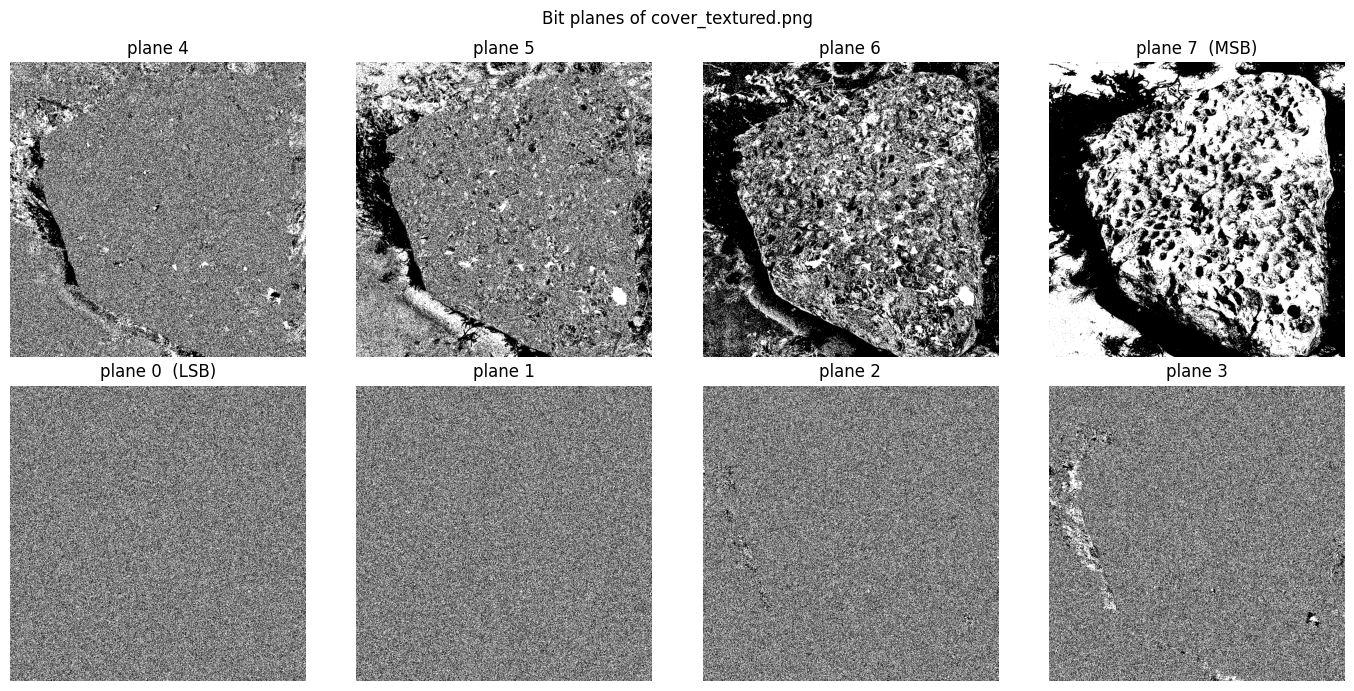

In [5]:
textured = np.asarray(Image.open(ROOT / "images/p2/cover_textured.png").convert("L")).astype(np.uint8)
smooth = np.asarray(Image.open(ROOT / "images/p2/cover_smooth.png").convert("L")).astype(np.uint8)

planes = bit_planes(textured)

fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for b in range(8):
    a = ax[1 - b // 4, b % 4]
    a.imshow(planes[b], cmap="gray", vmin=0, vmax=1)
    a.set_title(f"plane {b}" + ("  (LSB)" if b == 0 else "  (MSB)" if b == 7 else ""))
    a.axis("off")
plt.suptitle("Bit planes of cover_textured.png")
plt.tight_layout()
plt.show()

### PSNR against the number of retained planes

keep 1 planes: PSNR = 11.89 dB
keep 2 planes: PSNR = 16.92 dB
keep 3 planes: PSNR = 23.00 dB
keep 4 planes: PSNR = 29.23 dB
keep 5 planes: PSNR = 35.71 dB
keep 6 planes: PSNR = 42.69 dB
keep 7 planes: PSNR = 51.14 dB
keep 8 planes: PSNR = inf dB

per-plane gain: 5.03 6.08 6.23 6.48 6.98 8.45 dB
mean gain      : 6.54 dB    20*log10(2) = 6.02 dB


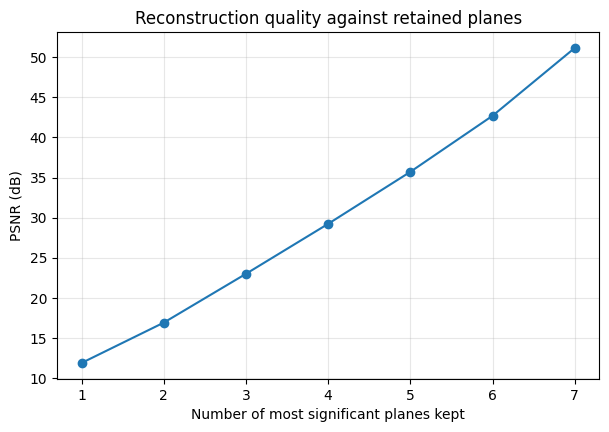

In [6]:
keeps = range(1, 9)
scores = [psnr(reconstruct(planes, k), textured) for k in keeps]

for k, s in zip(keeps, scores):
    print(f"keep {k} planes: PSNR = {s:.2f} dB")

gains = np.diff(scores[:-1])   # last step is to infinity
print("\nper-plane gain:", " ".join(f"{g:.2f}" for g in gains), "dB")
print("mean gain      :", f"{gains.mean():.2f} dB    20*log10(2) = {20 * np.log10(2):.2f} dB")

plt.figure(figsize=(7, 4.5))
plt.plot(list(keeps)[:-1], scores[:-1], marker="o")
plt.xlabel("Number of most significant planes kept")
plt.ylabel("PSNR (dB)")
plt.title("Reconstruction quality against retained planes")
plt.grid(True, alpha=0.3)
plt.show()

**Measure the gain per plane and explain why that value is not a coincidence.**

The measured gains are 5.03, 6.08, 6.23, 6.48, 6.98 and 8.45 dB, so each extra plane is worth
close to **6 dB**.

Keeping the top $n$ planes is the same as quantising the intensity with step
$\Delta = 2^{8-n}$. Adding one more plane halves $\Delta$, which divides the mean squared
error by 4, so the PSNR rises by

$$10\log_{10} 4 = 20\log_{10} 2 = 6.02\ \text{dB}.$$

This is the 6 dB per bit rule. It is not a coincidence: one extra bit doubles the number of
levels, and doubling the resolution is a factor of 4 in error power. It follows from binary
place value, so any image gives the same 6 dB.

The gain drifts above 6 dB at the fine end and falls below it at the coarse end, where only
one or two planes remain and the quantisation error is no longer small compared with the
signal itself.

### The intensity ramp, binary against Gray code

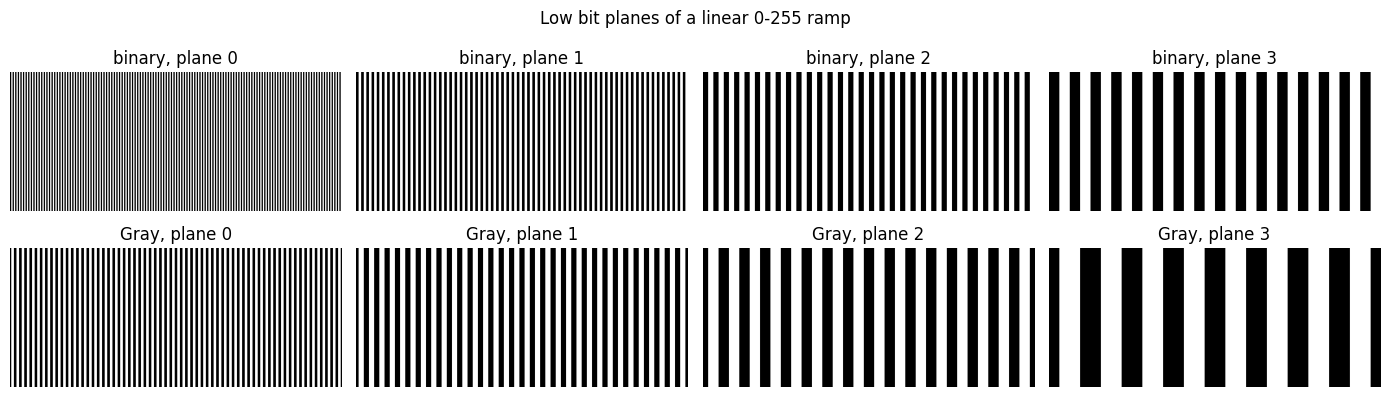

In [7]:
ramp = np.tile(np.arange(256, dtype=np.uint8), (64, 1))
ramp_planes = bit_planes(ramp)
gray_planes = bit_planes(gray_encode(ramp))

fig, ax = plt.subplots(2, 4, figsize=(14, 4))
for b in range(4):
    ax[0, b].imshow(ramp_planes[b], cmap="gray", vmin=0, vmax=1, aspect="auto")
    ax[0, b].set_title(f"binary, plane {b}")
    ax[1, b].imshow(gray_planes[b], cmap="gray", vmin=0, vmax=1, aspect="auto")
    ax[1, b].set_title(f"Gray, plane {b}")
for a in ax.ravel():
    a.axis("off")
plt.suptitle("Low bit planes of a linear 0-255 ramp")
plt.tight_layout()
plt.show()

**Identify the structure the low planes of the ramp show that the natural image does not, then
explain the difference under Gray coding.**

The ramp's low planes are exact **periodic square waves**: plane $b$ toggles every $2^b$
columns, so it has period $2^{b+1}$. Plane 0 alternates every column, plane 1 every two
columns, and so on. The same planes of the photograph look like noise.

The reason is the content, not the slicing. The ramp's intensity is a deterministic function
of position, so its low bits are too. In a photograph the low bits are set by sensor noise and
fine texture, which are uncorrelated between neighbouring pixels. Bit planes are therefore not
inherently noisy — that is what makes the LSB a good hiding place in 2.2.

**Under Gray coding** consecutive levels differ in exactly one bit, so a one-level step flips
one plane instead of several. In straight binary the planes all switch together at the
$2^b$ boundaries, which is what produces the aligned nested square waves, and at $127 \to 128$
all eight bits flip at once for a change of one grey level. The Gray planes still alternate
but their transitions are staggered rather than aligned, and no position has many planes
switching together. The practical benefit is that a single corrupted bit can no longer move
the intensity by 128 levels.

## 2.2 — Hide and recover a payload

### Decode the supplied stego image

In [8]:
stego_given = np.asarray(Image.open(ROOT / "images/p2/decode_me.png").convert("L")).astype(np.uint8)

allbits = extract_lsb(stego_given, stego_given.size)

sync = allbits[:8]
print("sync marker :", sync, " expected [1 0 1 0 1 0 1 0]")
print("sync ok     :", np.array_equal(sync, np.array([1, 0, 1, 0, 1, 0, 1, 0], dtype=np.uint8)))

ph = int("".join(map(str, allbits[8:16])), 2)
pw = int("".join(map(str, allbits[16:24])), 2)
print(f"payload     : {ph} x {pw} = {ph * pw} bits")

payload = allbits[24 : 24 + ph * pw].reshape(ph, pw)

sync marker : [1 0 1 0 1 0 1 0]  expected [1 0 1 0 1 0 1 0]
sync ok     : True
payload     : 64 x 64 = 4096 bits


### Recovered payload, PSNR, and difference map

PSNR(stego, clean cover) = 75.24 dB
max |stego - cover|      = 1
pixels changed           = 2039 of 4120 bit-carrying positions (49.5%)
rows containing a change = [0 1 2 3 4]


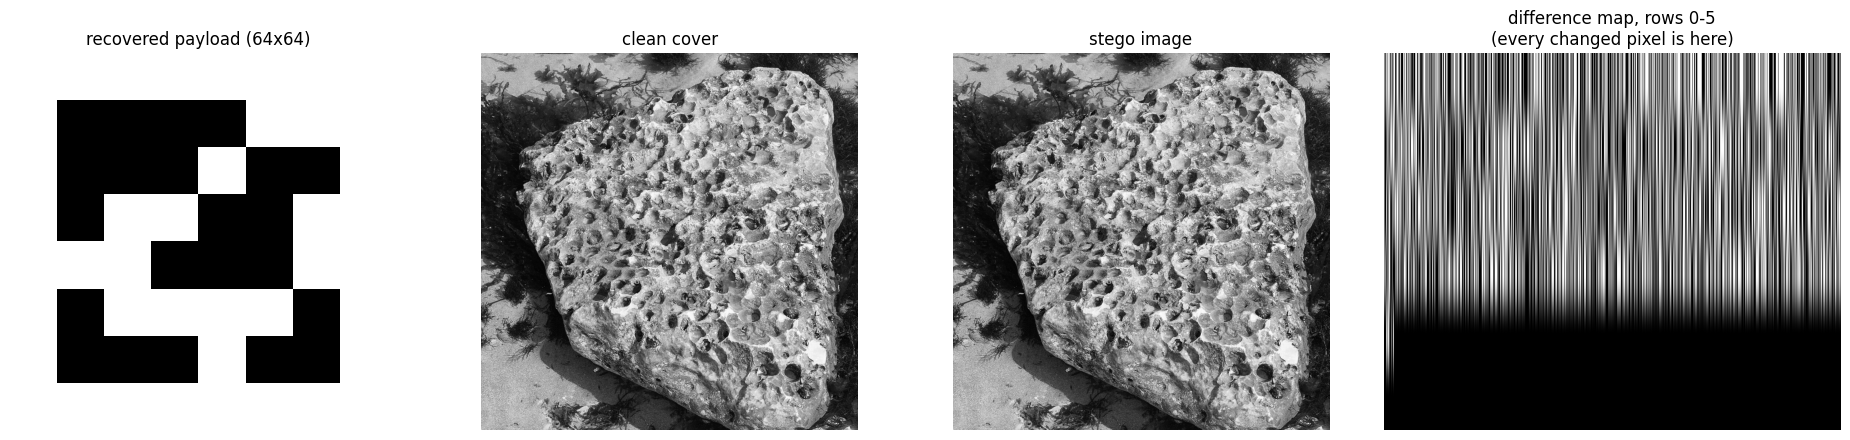

In [9]:
diff = (stego_given.astype(int) != textured.astype(int))
n_carrying = 24 + ph * pw

print(f"PSNR(stego, clean cover) = {psnr(stego_given, textured):.2f} dB")
print(f"max |stego - cover|      = {np.abs(stego_given.astype(int) - textured.astype(int)).max()}")
print(f"pixels changed           = {diff.sum()} of {n_carrying} bit-carrying positions "
      f"({diff.sum() / n_carrying:.1%})")
print(f"rows containing a change = {np.flatnonzero(diff.any(1))}")

# 4120 bits in raster order only reach row 4 of a 1024-wide image, so the whole-image
# map is 99.8% black and shows nothing. Plot the strip the changes actually live in.
fig, ax = plt.subplots(1, 4, figsize=(19, 4.5))
ax[0].imshow(payload, cmap="gray"); ax[0].set_title(f"recovered payload ({ph}x{pw})")
ax[1].imshow(textured, cmap="gray"); ax[1].set_title("clean cover")
ax[2].imshow(stego_given, cmap="gray"); ax[2].set_title("stego image")
ax[3].imshow(diff[:6], cmap="gray", aspect="auto")
ax[3].set_title("difference map, rows 0-5\n(every changed pixel is here)")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

**Say whether you could have detected the payload by eye, and account for why only about half
of the bit-carrying positions actually changed.**

**No.** The embedding only ever touches bit 0, so no pixel moves by more than one grey level
out of 256, giving a PSNR of 75.24 dB. That is far above the roughly 40 dB at which distortion
starts to be visible, and the cover and the stego image above look identical.

**On the count.** 2039 of the 4120 bit-carrying positions differ, about 49.5%. Every one of
those positions was written. The write is simply a no-op wherever the cover's original LSB
already equalled the bit being embedded, which for uncorrelated data happens half the time. So
counting changed pixels undercounts the positions actually used by a factor of two, and a
steganalyst working from that count would underestimate the payload length by the same factor.

The difference map shows where the embedding sits: only 2039 pixels out of 1048576 changed,
0.19%, and all of them are in rows 0 to 4, because 4120 bits written in raster order across a
1024-wide image run out partway through row 4. That is also why I plot the strip rather than
the full image, which at this density comes out solid black. Computing the map at all needs the
clean cover, which is exactly what an attacker does not have.

### The same payload in both covers

The handout asks for at least 256x256 bits, so the recovered payload is upsampled by 4 in each
direction to give 65 536 bits.

In [10]:
big_payload = np.kron(payload, np.ones((4, 4), dtype=np.uint8))
print("enlarged payload:", big_payload.shape, "=", big_payload.size, "bits")

stego_t = embed_lsb(textured, big_payload.ravel())
stego_s = embed_lsb(smooth, big_payload.ravel())

R = big_payload.size // 1024          # embedded region = first R rows

print(f"\n{'cover':10s} {'PSNR (dB)':>10} {'pixels changed':>16}")
for name, c, s in [("textured", textured, stego_t), ("smooth", smooth, stego_s)]:
    print(f"{name:10s} {psnr(c, s):10.2f} {int((c != s).sum()):16d}")

enlarged payload: (256, 256) = 65536 bits

cover       PSNR (dB)   pixels changed
textured        63.16            32921
smooth          63.19            32692


PSNR and the change counts are effectively identical, so the evidence for which cover is the
worse hiding place has to be local rather than global.

In [11]:
print(f"{'cover':10s} {'median tile var':>16} {'noise / local var':>19}")

for name, c, s in [("textured", textured, stego_t), ("smooth", smooth, stego_s)]:
    reg = c[:R].astype(np.float64)
    v = reg.reshape(R // 8, 8, 128, 8).swapaxes(1, 2).var(axis=(2, 3)).ravel()
    d = (s[:R].astype(np.float64) - reg) ** 2
    tn = d.reshape(R // 8, 8, 128, 8).swapaxes(1, 2).mean(axis=(2, 3)).ravel()
    print(f"{name:10s} {np.median(v):16.2f} {np.median(tn / np.maximum(v, 1e-9)):19.5f}")

cover       median tile var   noise / local var


textured             207.94             0.00241
smooth                13.17             0.03775


**Show which cover is the materially worse hiding place, and explain why PSNR cannot see it.**

The **smooth** cover is the worse hiding place. The embedding is identical in both cases —
same payload, same positions, same $\pm 1$ change, and the same number of modified pixels — so
the PSNRs come out at 63.16 dB and 63.19 dB, indistinguishable.

What differs is what the change has to hide behind. In the embedded region the median $8\times8$
tile variance is about **208** for the textured cover and **13** for the smooth one. Measuring
the embedding as a fraction of the local signal it must hide in gives $2.4\times10^{-3}$ against
$3.8\times10^{-2}$, so the perturbation is roughly **16 times larger relative to local content**
in the smooth cover.

PSNR cannot see this because it is a single global average of squared error. It depends only on
how much total error energy was added, not on where that energy landed or what was underneath
it. Two embeddings that flip the same number of pixels by one level have almost the same PSNR
whatever the cover. Detectability, by contrast, depends on the error *relative to local
content*: a one-level change on texture spanning tens of levels is masked, while the same change
on a near-constant patch is a large share of the local range. Any argument about hiding places
therefore needs a local measure, which is why the tile-variance ratio is the evidence here.

## 2.3 — Survive the channel

Block-DCT QIM: one coefficient (2,2) per JPEG-aligned 8x8 block, bit 0 on the lattice {k*48}
and bit 1 on {k*48 + 24}, each of the 128 bits repeated over 128 blocks and majority-voted.

In [12]:
# Orthonormal 8x8 DCT-II matrix, built with NumPy (no scipy)
_k = np.arange(8)
_D = np.cos(np.pi * (2 * _k[None, :] + 1) * _k[:, None] / 16)
_D[0, :] *= np.sqrt(1 / 8)
_D[1:, :] *= np.sqrt(2 / 8)


def _to_blocks(img):
    H, W = img.shape
    return img.reshape(H // 8, 8, W // 8, 8).swapaxes(1, 2)


def _from_blocks(blocks):
    nh, nw = blocks.shape[:2]
    return blocks.swapaxes(1, 2).reshape(nh * 8, nw * 8)


def _bit_of_block(nb, n, seed):
    """Which bit each block carries, under a fixed pseudorandom scatter."""
    order = np.random.default_rng(seed).permutation(nb)
    assign = np.empty(nb, dtype=np.int64)
    assign[order] = np.arange(nb) % n
    return assign


def embed_robust(cover, bits, delta=48.0, coef=(2, 2), seed=12345):
    bits = np.asarray(bits, dtype=np.uint8).ravel()
    n = len(bits)
    u, v = coef

    blocks = _to_blocks(cover.astype(np.float64))
    nh, nw = blocks.shape[:2]
    nb = nh * nw

    C = (_D @ blocks @ _D.T).reshape(nb, 8, 8)

    carried = bits[_bit_of_block(nb, n, seed)]
    offset = np.where(carried == 1, delta / 2, 0.0)

    c = C[:, u, v]
    C[:, u, v] = delta * np.round((c - offset) / delta) + offset

    rec = _D.T @ C.reshape(nh, nw, 8, 8) @ _D

    return np.clip(np.round(_from_blocks(rec)), 0, 255).astype(np.uint8)


def extract_robust(stego, cover, n, delta=48.0, coef=(2, 2), seed=12345):
    """Blind: `cover` is accepted to match the starter signature, never read."""
    u, v = coef

    blocks = _to_blocks(stego.astype(np.float64))
    nh, nw = blocks.shape[:2]
    nb = nh * nw

    c = (_D @ blocks @ _D.T).reshape(nb, 8, 8)[:, u, v]

    res = np.mod(c, delta)
    d0 = np.minimum(res, delta - res)
    d1 = np.abs(res - delta / 2)
    hard = (d1 < d0).astype(np.int64)

    assign = _bit_of_block(nb, n, seed)
    votes = np.bincount(assign, weights=hard, minlength=n)
    counts = np.bincount(assign, minlength=n)

    return (votes > counts / 2).astype(np.uint8)

### Stego PSNR and clean recovery

In [13]:
message = np.random.default_rng(7).integers(0, 2, 128).astype(np.uint8)

stego_qim = embed_robust(textured, message)
stego_naive = embed_lsb(textured, message)

print(f"PSNR(cover, QIM stego) = {psnr(textured, stego_qim):.2f} dB   (requirement >= 40)")
print(f"clean BER              = {ber(extract_robust(stego_qim, textured, 128), message)}")
print(f"max |cover - stego|    = {np.abs(textured.astype(int) - stego_qim.astype(int)).max()} levels")

PSNR(cover, QIM stego) = 43.11 dB   (requirement >= 40)
clean BER              = 0.0
max |cover - stego|    = 5 levels


### BER against both channels, mine and naive LSB

In [14]:
sigmas = [0, 1, 2, 5, 10, 20]
ber_qim, ber_naive = [], []

for s in sigmas:
    ber_qim.append(ber(extract_robust(degrade_gaussian(stego_qim, s), textured, 128), message))
    ber_naive.append(ber(extract_lsb(degrade_gaussian(stego_naive, s), 128), message))

jpeg_qim = ber(extract_robust(degrade_jpeg(stego_qim, 75), textured, 128), message)
jpeg_naive = ber(extract_lsb(degrade_jpeg(stego_naive, 75), 128), message)

print(f"{'sigma':>6} {'QIM BER':>10} {'naive BER':>11}")
for s, a, b in zip(sigmas, ber_qim, ber_naive):
    print(f"{s:6d} {a:10.4f} {b:11.4f}")

print(f"\nJPEG q75   QIM BER = {jpeg_qim:.4f}    naive BER = {jpeg_naive:.4f}")
print("\nrequirement: zero errors at sigma=5 and at JPEG q75")
print(f"  sigma=5  : {'PASS' if ber_qim[sigmas.index(5)] == 0 else 'FAIL'}")
print(f"  JPEG q75 : {'PASS' if jpeg_qim == 0 else 'FAIL'}")

 sigma    QIM BER   naive BER
     0     0.0000      0.0000
     1     0.0000      0.5625
     2     0.0000      0.5781
     5     0.0000      0.5625
    10     0.0000      0.5000
    20     0.2422      0.5156

JPEG q75   QIM BER = 0.0000    naive BER = 0.5391

requirement: zero errors at sigma=5 and at JPEG q75
  sigma=5  : PASS
  JPEG q75 : PASS


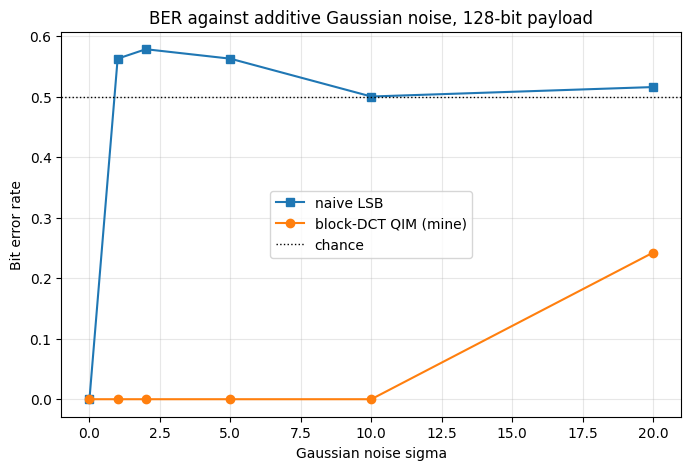

In [15]:
plt.figure(figsize=(8, 5))
plt.plot(sigmas, ber_naive, marker="s", label="naive LSB")
plt.plot(sigmas, ber_qim, marker="o", label="block-DCT QIM (mine)")
plt.axhline(0.5, color="k", ls=":", lw=1, label="chance")
plt.xlabel("Gaussian noise sigma")
plt.ylabel("Bit error rate")
plt.title("BER against additive Gaussian noise, 128-bit payload")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### (a) Does the decoder need the clean cover?

**Blind** — `extract_robust` accepts `cover` only to match the starter signature and never
reads it. QIM is blind by construction: the bit is carried by *which lattice* the coefficient
was quantised onto, and that is an absolute property of the received value rather than a
comparison against an original.

A cover-assisted decoder is solving an easier problem, since it can subtract the original and
read the residual directly, which tolerates far more channel damage. The cost is that the
receiver must already hold the entire cover image, which in most realistic uses defeats the
point of hiding data in it. Going the other way, from cover-assisted to blind, is the hard
direction and needs exactly what I used here: a quantisation-based rather than
difference-based embedding, so the decision rule requires no reference.

### (b) What are you trading?

$\mathrm{PSNR} \ge 40$ dB means $\mathrm{MSE} \le 255^2/10^4 = 6.50$, so the total squared
error allowed over the image is $6.50 \times 1024^2 = 6.8\times10^6$. My scheme spends
$\mathrm{MSE} = 3.18$, a total of $3.3\times10^6$, which is about half the budget and lands at
43.11 dB.

So the 40 dB floor is **not** the binding constraint at 128 bits. I could roughly double the
step and still pass; I do not need to, because the error rate is already zero with margin. What
the spare budget buys is redundancy: all 16 384 blocks are used to carry 128 bits, a ratio of
128:1.

### Design paragraph

The problem fixes the payload at 128 bits and fixes imperceptibility at 40 dB, which leaves
redundancy as the only free variable, so I spent it all on robustness and gave up capacity. The
same scheme at one bit per block would carry 16 384 bits — 128 times the payload — but each bit
would then rest on a single coefficient and would no longer survive $\sigma = 5$. Instead each
bit is repeated over 128 scattered blocks and majority-voted, which turns a small per-block
error rate into zero bit errors, and I finish at 43 dB with distortion budget still unspent. I
therefore sit in the corner of the triangle that sacrifices rate to buy robustness, which is the
right corner when the payload is fixed at 128 bits in a megapixel image.

### What each channel breaks

The two channels fail different designs, which is why meeting both is the real constraint.
Gaussian noise is broadband and random: it perturbs every coefficient a little and so destroys
anything whose decision margin is smaller than the noise. Naive LSB has a margin of half a grey
level and is already at chance by $\sigma = 1$. The defence is a large margin plus averaging,
which $\Delta = 48$ and the 128-fold repetition provide.

JPEG is deterministic and does not add noise so much as delete information: it discards high
frequencies outright and coarsely requantises the rest. A scheme hiding data in high
frequencies, or one whose lattice is misaligned with the JPEG quantiser, is destroyed no matter
how large its margin. Choosing a mid-low coefficient and making both $\Delta$ and $\Delta/2$
multiples of the JPEG q75 step means requantisation lands back on the lattice, so JPEG costs
essentially nothing. The scheme finally fails at $\sigma = 20$ (BER 0.24), where per-block
errors approach the level no amount of voting can recover.